<div align="center">

# <span style="color: #3498db;">CA2 - Genetic & Game</span>

**<span style="color:rgb(247, 169, 0);">Mahdi Yari</span> - <span style="color:rgb(143, 95, 195);">810102532**

</div>


<div style="font-family: Arial, sans-serif; line-height: 1.6;">

### 📊 Matplotlib – Data Visualization in Python  

matplotlib is a python library that is mainly used for data visualization. This library allows you to plot different type of figures including scatters and histograms. In the first part of this project you are supposed to implement a genetic algorithm. To visualize plots that are required in the project description use plotting as much as you can because it gives a great insight on what is happening during each run. It also helps you to compare your results whenevever you want to understand effect of different parameters during different runs.
For more information, check [this notebook](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/04.00-Introduction-To-Matplotlib.ipynb) and visit [the website](https://matplotlib.org/stable/tutorials/pyplot.html#sphx-glr-tutorials-pyplot-py).

# <span style="color: #3498db;">Genetic Algorithm</span>

In [1]:
import random
import itertools
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# These functions are given as samples to use in the algorithm
def getTargetFunction(functionName="sin_cos"):
    def sinCosFunction(t):
        """Target function: sin(2πt) + 0.5*cos(4πt)."""
        return np.sin(2 * np.pi * t) + 0.5 * np.cos(4 * np.pi * t)

    def linearFunction(t):
        """Simple linear function: y = 2t + 1."""
        return 2 * t + 1

    def quadraticFunction(t):
        """Quadratic function: y = 4t^2 - 4t + 2."""
        return 4 * (t**2) - 4 * t + 2

    def cubicFunction(t):
        """Cubic function: y = 8t^3 - 12t^2 + 6t."""
        return 8 * (t**3) - 12 * (t**2) + 6 * t

    def gaussianFunction(t):
        """Gaussian function centered at t=0.5."""
        mu = 0.5
        sigma = 0.1  # Adjust sigma to control the width of the peak
        return np.exp(-((t - mu) ** 2) / (2 * sigma**2))

    def squareWaveFunction(t):
        """Approximation of a square wave. Smoothed for better Fourier approximation."""
        return 0.5 * (np.sign(np.sin(2 * np.pi * t)) + 1)

    def sawtoothFunction(t):
        """Sawtooth wave, normalized to [0, 1]."""
        return (t * 5) % 1

    def complexFourierFunction(t):
        return (
            np.sin(2 * np.pi * t)
            + 0.3 * np.cos(4 * np.pi * t)
            + 0.2 * np.sin(6 * np.pi * t)
            + 0.1 * np.cos(8 * np.pi * t)
        )

    def polynomialFunction(t):
        return 10 * (t**5) - 20 * (t**4) + 15 * (t**3) - 4 * (t**2) + t + 0.5

    functionOptions = {
        "sin_cos": sinCosFunction,
        "linear": linearFunction,
        "quadratic": quadraticFunction,
        "cubic": cubicFunction,
        "gaussian": gaussianFunction,
        "square_wave": squareWaveFunction,
        "sawtooth": sawtoothFunction,
        "complex_fourier": complexFourierFunction,
        "polynomial": polynomialFunction,
    }

    selectedFunction = functionOptions.get(functionName.lower())
    if selectedFunction:
        return selectedFunction

<div style="color:rgb(235, 66, 32); font-weight: bold;">⚠️ Important Note:</div>  

Using **NumPy arrays** allows you to perform operations on vectors **more efficiently** and **faster**.

**Avoid using `for` loops** whenever possible, as vectorized operations in NumPy are **optimized for performance** and significantly reduce execution time.  


In [3]:
numCoeffs = 41
populationSize = 100
generations = 200
mutationRate = 0.02
functionRange = (-np.pi, np.pi)
sampleCount = 100
gang_ch = 4
T = 10

In [4]:
tSamples = np.linspace(functionRange[0], functionRange[1], sampleCount)
fSamples = getTargetFunction("sin_cos")(tSamples)
list_of_points = tSamples
real_values = fSamples
mx_point = np.max(np.abs(real_values))
limit = mx_point * np.sqrt(2)
chromosomes = []
for _ in range(populationSize):
    chromosome = np.random.uniform(-limit, limit, size = numCoeffs)
    chromosomes.append(chromosome)

In [5]:
def fourier_series(chromosome, t_values, T):
    a0 = chromosome[0]
    result = np.full_like(t_values, a0)
    omega = 2 * np.pi / T
    for i in range(1, 21):
        a_n = chromosome[2 * i - 1]
        b_n = chromosome[2 * i]
        result += a_n * np.cos(i * omega * t_values) + b_n * np.sin(i * omega * t_values)
    return result
xx = []
for i in range(len(chromosomes)):
    xx.append(fourier_series(chromosomes[i], list_of_points, T))

In [6]:
def fitness_1(ans, true_values):
    out = np.sqrt(np.mean((ans - true_values) ** 2))
    return out

def fitness_2(ans, true_values):
    out = np.mean(np.abs(ans - true_values))
    return out

def fitness_3(ans, true_values):
    out = np.corrcoef(ans, true_values)[0, 1]
    return 1 - out

def fitness_4(ans, true_values):
    x = ans
    y = true_values
    mean_x = np.mean(x)
    mean_y = np.mean(y)
    var_x = np.var(x)
    var_y = np.var(y)
    cov_xy = np.mean((x - mean_x) * (y - mean_y))
    out = (2 * cov_xy) / (var_x + var_y + (mean_x - mean_y)**2 + 1e-12)
    return 1 - out

def fitness_5(ans, true_values):
    x = ans
    y = true_values
    num = np.dot(x, y)
    denom = np.linalg.norm(x) * np.linalg.norm(y) + 1e-12
    out = num / denom
    return 1 - out
def fitness_idx(i, xx, real_values):
    out_fitnees = float(fitness_5(xx[i], real_values))
    return out_fitnees
def fitness_idx(i, xx, real_values):
    out_fitnees = float(fitness_4(xx[i], real_values))
    return out_fitnees

In [7]:
def choice_parent(chromosomes, xx, real_values, number=8):
    top = random.sample(range(len(chromosomes)), number)
    tmp = []
    for i in top:
        tmp += [(fitness_idx(i, xx, real_values), i)]
    tmp.sort()
    for i, j in tmp:
        pass
    return tmp[0][1], tmp[1][1]


def choice_parent_roulette(chromosomes, xx, real_values):
    errors = []
    for i in range(len(chromosomes)):
        errors.append(fitness_idx(i, xx, real_values))
    scores = 1.0 / (np.array(errors) + 1e-6)
    probs = scores / np.sum(scores)
    parents = np.random.choice(len(chromosomes), size=2, replace=False, p=probs)
    return parents[0], parents[1]

def choice_parent_rank(chromosomes, xx, real_values):
    errors = []
    for i in range(len(chromosomes)):
        errors.append(fitness_idx(i, xx, real_values))
    sorted_idx = np.argsort(errors)
    N = len(chromosomes)
    ranks = np.zeros(N)
    for rank, idx in enumerate(sorted_idx):
        ranks[idx] = N - rank
    probs = ranks / np.sum(ranks)
    parents = np.random.choice(N, size=2, replace=False, p=probs)
    return parents[0], parents[1]



In [8]:
def crossover(p1, p2, chromosomes):
    ch1 = chromosomes[p1]
    ch2 = chromosomes[p2]
    point = random.randint(1, len(ch1) - 2)
    new_ch_1 = np.concatenate([ch1[:point], ch2[point:]])
    new_ch_2 = np.concatenate([ch2[:point], ch1[point:]])
    return new_ch_1, new_ch_2
def crossover_2(p1, p2, chromosomes):
    ch1 = chromosomes[p1]
    ch2 = chromosomes[p2]
    point_1 = random.randint(1, len(ch1) - 2)
    point_2 = random.randint(point_1 + 1, len(ch1) - 1)
    new_ch_1 = np.concatenate([ch1[:point_1], ch2[point_1:point_2], ch1[point_2:]])
    new_ch_2 = np.concatenate([ch2[:point_1], ch1[point_1:point_2], ch2[point_2:]])
    return new_ch_1, new_ch_2
def crossover_3(p1, p2, chromosomes):
    ch1 = chromosomes[p1]
    ch2 = chromosomes[p2]
    new_ch_1 = np.empty_like(ch1)
    new_ch_2 = np.empty_like(ch2)
    for i in range(len(ch1)):
        if random.random() < 0.5:
            new_ch_1[i] = ch1[i]
            new_ch_2[i] = ch2[i]
        else:
            new_ch_1[i] = ch2[i]
            new_ch_2[i] = ch1[i]
    return new_ch_1, new_ch_2



In [9]:
def mutate(ch, rate = mutationRate, limit = limit):
    for i in range(len(ch)):
        if random.random() < rate:
            ch[i] = random.uniform(-limit, limit)
    return ch

In [10]:
def next_generation(chromosomes, xx, real_values, list_of_points, T):
    fitness_idx_pairs = []
    for i in range(len(chromosomes)):
        fitness_idx_pairs.append((fitness_idx(i, xx, real_values), i))
    fitness_idx_pairs.sort()
    best_fitness = fitness_idx_pairs[0][0]
    elite_pairs = fitness_idx_pairs[:gang_ch]
    new_chroms = []
    new_xx     = []
    for _, idx in elite_pairs:
        new_chroms.append(chromosomes[idx])
        new_xx.append(xx[idx])
    while len(new_chroms) < populationSize:
        i1, i2 = choice_parent(chromosomes, xx, real_values)
        c1, c2 = crossover_3(i1, i2, chromosomes)
        c1 = mutate(c1)
        c2 = mutate(c2)
        new_chroms.append(c1)
        new_xx.append(fourier_series(c1, list_of_points, T))
    fitness_idx_pairs = []
    for i in range(len(chromosomes)):
        fitness_idx_pairs.append((fitness_idx(i, xx, real_values), i))
    fitness_idx_pairs.sort()  
    return new_chroms, new_xx, best_fitness

In [11]:
for i in range(generations):
    chromosomes, xx, best_fitness = next_generation(chromosomes, xx, real_values, list_of_points, T)
    print(f"generation {i} best fitness is: {best_fitness}")

generation 0 best fitness is: 0.8870155983235676
generation 1 best fitness is: 0.8349356274915497
generation 2 best fitness is: 0.8314918991943739
generation 3 best fitness is: 0.7930262334015664
generation 4 best fitness is: 0.7856883655607582
generation 5 best fitness is: 0.7610649431186579
generation 6 best fitness is: 0.7386439779616761
generation 7 best fitness is: 0.724694196128101
generation 8 best fitness is: 0.7075865634912271
generation 9 best fitness is: 0.6826019045876505
generation 10 best fitness is: 0.6772984639329832
generation 11 best fitness is: 0.6347977325929711
generation 12 best fitness is: 0.6347977325929711
generation 13 best fitness is: 0.5972009855513987
generation 14 best fitness is: 0.5972009855513987
generation 15 best fitness is: 0.5940247641732026
generation 16 best fitness is: 0.5834448940582362
generation 17 best fitness is: 0.5554528958749194
generation 18 best fitness is: 0.5383166604073517
generation 19 best fitness is: 0.5343137352324339
generation 

Scale factor = 0.8463


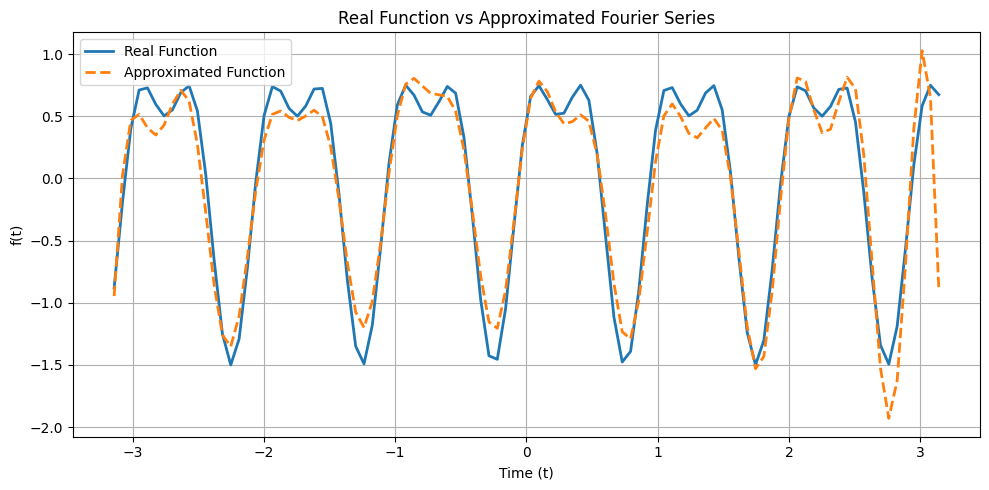

In [12]:
min_err = []
for i in range(len(xx)):
    out = fitness_idx(i, xx, real_values)
    min_err.append(out)
mn = np.argmin(min_err)
ans = xx[mn]
scale  = np.dot(real_values, ans) / np.dot(ans, ans) + 1e-12 
print(f"Scale factor = {scale:.4f}")
ans = ans * scale

plt.figure(figsize=(10, 5))
plt.plot(list_of_points, real_values,   label="Real Function", linewidth=2)
plt.plot(list_of_points, ans, '--', label="Approximated Function", linewidth=2)
plt.title("Real Function vs Approximated Fourier Series")
plt.xlabel("Time (t)")
plt.ylabel("f(t)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


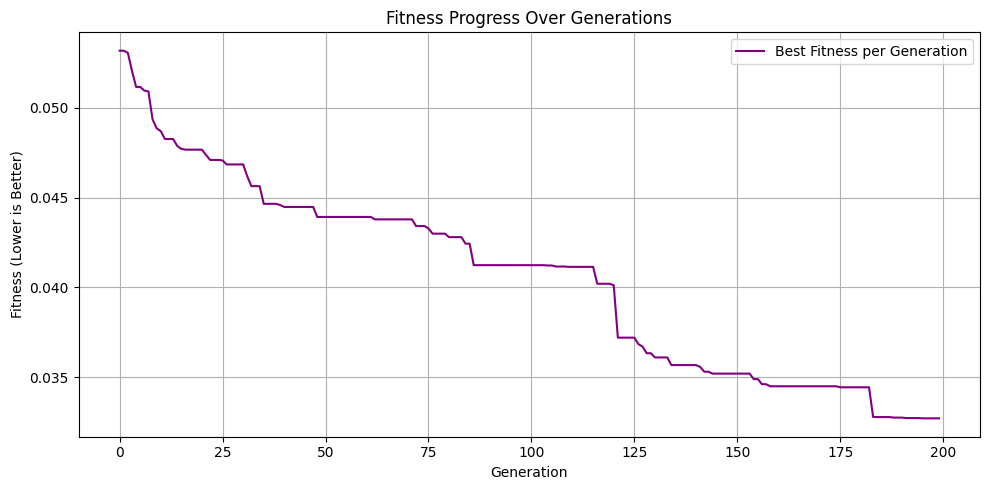

In [13]:
fitness_history = []
for gen in range(generations):
    chromosomes, xx, best_fit = next_generation(chromosomes, xx, real_values, list_of_points, T)
    fitness_history.append(best_fit)
plt.figure(figsize=(10, 5))
plt.plot(range(generations), fitness_history, label="Best Fitness per Generation", color='purple')
plt.xlabel("Generation")
plt.ylabel("Fitness (Lower is Better)")
plt.title("Fitness Progress Over Generations")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

برای کروموزومی که در نظر گرفته اید فضای حالت آن را محاسبه کنید.

کروموزوم‌هایی که داریم، لیست‌هایی شامل ۴۱ ضریب هستند:
و هر کدام از این 41 ژن یک مقداری بین -pi تا +pi دارند
پس فضای حالت میشه 41 به توان 2pi

دو تا از ایدههایی که از نظر شما میتواند باعث سریعتر همگرا شدن این مسئله شود را توضیح دهید

با کاهش بازه‌ای که برای مقداردهی اولیه به ضرایف سری فوریه استفاده می‌شود، جمعیت اولیه به‌جای پخش شدن در کل فضای حالت، در ناحیه‌ای متمرکز از فضای جستجو قرار می‌گیرد.
این موضوع می‌تواند منجر به کاهش پراکندگی جمعیت اولیه شود و در نتیجه، الگوریتم با تمرکز بیشتری روی بهینه‌سازی عمل کند و سریع‌تر به جواب‌های بهتر برسد.

با کاهش نرخ جهش، تغییرات ناگهانی در جمعیت کنترل شده و روند بهینه‌سازی به‌صورت تدریجی‌تر و هدفمندتر انجام می‌شود.
این کار باعث می‌شود که الگوریتم به جای پرش‌های تصادفی، روی پالایش جواب‌های موجود تمرکز کند و به‌صورت پایدار به سمت جواب بهینه حرکت کند.

استراتژیهای متفاوتی برای انتخاب نسل بعد در الگوریتمهای ژنتیک وجود دارد. درباره دو مورد از آنها
توضیح دهید.

(Tournament Selection):
در این روش، به‌صورت تصادفی چند فرد از جمعیت انتخاب می‌شوند (معمولاً 2 تا 5 نفر)، و از میان آن‌ها فردی که بهترین مقدار تابع برازندگی را دارد، برای تولید نسل بعد انتخاب می‌شود.
این روش هم سادگی محاسباتی دارد و هم فشار انتخابی مناسبی ایجاد می‌کند، چرا که احتمال انتخاب افراد بهتر بیشتر است ولی همچنان شانس برای افراد ضعیف‌تر وجود دارد.

(Roulette Wheel Selection):
در این روش، احتمال انتخاب هر فرد متناسب با مقدار تابع برازندگی‌اش است.
می‌توان این فرآیند را مشابه یک چرخ رولت در نظر گرفت که هر فرد سهمی از چرخ را دارد و این سهم وابسته به میزان برازندگی اوست.
بنابراین، هرچه یک فرد برازندگی بالاتری داشته باشد، احتمال انتخاب شدنش نیز بیشتر است.

یکی از چالشهای اصلی در الگوریتمهای ژنتیک، جلوگیری از همگرایی زودرس )Premature
Convergence( است. این پدیده زمانی رخ میدهد که جمعیت به سرعت به یک نقطه بهینه محلی
همگرا میشود و از کشف راهحلهای بهتر باز میماند. دو روش برای جلوگیری از همگرایی زودرس در
الگوریتم ژنتیک نام ببرید و توضیح دهید که هر کدام چگونه باعث افزایش تنوع ژنتیکی در جمعیت
میشوند.

(Mutation Rate):

با افزایش نرخ جهش، امکان ایجاد تغییرات تصادفی در کروموزوم‌ها بیشتر می‌شود. این تغییرات می‌توانند ژن‌های جدیدی را وارد جمعیت کنند که منجر به افزایش تنوع ژنتیکی می‌شود.
این تنوع باعث می‌شود که الگوریتم در نواحی مختلف فضای جست‌وجو حرکت کند و احتمال گرفتار شدن در بهینه‌های محلی کاهش یابد.

(Crossover):
انتخاب روش‌هایی مانند چند نقطه‌ای  یا یکنواخت می‌تواند باعث ترکیب بهتر و عمیق‌تر ژن‌ها بین والدین شود.
این ترکیب قوی‌تر، ژن‌های متنوع‌تری در نسل بعد ایجاد می‌کند و در نتیجه، تنوع ژنتیکی افزایش می‌یابد.
همچنین، استفاده‌ی کنترل‌شده باید با دقت انجام شود، زیرا نگه‌داشتن بیش‌ازحد افراد برتر می‌تواند منجر به کاهش تنوع جمعیت و همگرایی زودرس شود.

کی از توابع خطایی که در کارهای آماری و مسائل یادگیری ماشین استفاده میشود تابع R-squared
است. نحوه کار این تابع را توضیح دهید و توضیح دهید آیا در انجام این مسئله میتواند کاربردی
باشد یا نه.

$$ R^2 = 1 - \frac{\sum (f_{\text{target}} - f_{\text{approx}})^2}{\sum (f_{\text{target}} - \bar{f}_{\text{target}})^2} $$

این معیار نشان می‌دهد که مدل تا چه حد توانسته تغییرات داده‌های واقعی را توضیح دهد. مقدار 
R2
  نزدیک به 1 به معنای برازش خوب مدل است.

# <span style="color: #3498db;">Minmax Algorithm</span>

In [2]:
import random
import numpy as np
from math import inf
import pygame
import time
from collections import Counter


pygame 2.6.1 (SDL 2.28.4, Python 3.11.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [4]:
def get_all_segments(board):
        segments = []
        n = 6
        for i in range(n):
            for j in range(n - 4):
                segments.append([board[i][j + k] for k in range(5)])
                segments.append([board[j + k][i] for k in range(5)])
        for i in range(n - 4):
            for j in range(n - 4):
                segments.append([board[i + k][j + k] for k in range(5)])
                segments.append([board[i + k][j + 4 - k] for k in range(5)])
        return segments
def evaluate_segment(seq):
    score_map = {0: 0, 1: 1, 2: 50, 3: 700, 4: 5000, 5: 100000}
    count = Counter(seq)
    if count[1] and not count[-1]:
        return -score_map[count[1]]
    elif count[-1] and not count[1]:
        return score_map[count[-1]]
    return 0


class PentagoGame:
    def __init__(self, ui=False, print=False, depth=2):
        self.board = np.zeros((6, 6), dtype=int)
        self.current_player = 1
        self.ui = ui
        self.depth = depth
        self.nodes_visited = 0
        self.total_nodes_visited = 0
        self.game_over = False
        self.result = None
        self.selected_block = None
        self.move_stage = 0  # 0: place piece, 1: select block, 2: rotate
        self.temp_piece = None
        self.print = print

        if ui:
            pygame.font.init()
            self.screen = pygame.display.set_mode((800, 600))
            pygame.display.set_caption("Pygame Board")
            # self.font = pygame.font.SysFont("Arial", 20)
            self.show_buttons = False
            self.buttons = {
                "rotate_cw": pygame.Rect(650, 200, 100, 50),
                "rotate_ccw": pygame.Rect(650, 300, 100, 50),
            }
            self.setup_controls()
            self.draw_board()

    def setup_controls(self):
        if self.show_buttons:
            pygame.draw.rect(self.screen, (144, 238, 144), self.buttons["rotate_cw"])   # Light Green
            pygame.draw.rect(self.screen, (173, 216, 230), self.buttons["rotate_ccw"])  # Light Blue

            self.screen.draw_text("CLOCKWISE", self.buttons["rotate_cw"].center)
            self.screen.draw_text("COUNTER-CLOCKWISE", self.buttons["rotate_ccw"].center)



    def hide_rotation_buttons(self):
        self.show_buttons = False

    def show_rotation_buttons(self):
        self.show_buttons = True

    def copy_board(self, board):
        return np.copy(board)

    def rotate_block(self, board, block, direction):
        row_start = (block // 2) * 3
        col_start = (block % 2) * 3
        sub = board[row_start : row_start + 3, col_start : col_start + 3]
        rotated = np.rot90(sub, 3 if direction == "cw" else 1)
        board[row_start : row_start + 3, col_start : col_start + 3] = rotated

    def get_possible_moves(self, board, player):
        moves = []
        for i in range(6):
            for j in range(6):
                if board[i][j] == 0:
                    for block in range(4):
                        for dir in ["cw", "ccw"]:
                            moves.append((i, j, block, dir))
        return moves

    def apply_move(self, board, move, player):
        new_board = self.copy_board(board)
        row, col, block, direction = move
        if new_board[row][col] != 0:
            return None
        new_board[row][col] = player
        self.rotate_block(new_board, block, direction)
        return new_board

    def check_winner(self, board):
        for i in range(6):
            for j in range(6):
                if board[i][j] == 0:
                    continue

                # Horizontal
                if j <= 1 and np.all(board[i, j : j + 5] == board[i][j]):
                    return board[i][j]

                # Vertical
                if i <= 1 and np.all(board[i : i + 5, j] == board[i][j]):
                    return board[i][j]

                # Diagonal
                if (
                    i <= 1
                    and j <= 1
                    and all(board[i + k][j + k] == board[i][j] for k in range(5))
                ):
                    return board[i][j]

                # Anti-diagonal
                if (
                    i <= 1
                    and j >= 4
                    and all(board[i + k][j - k] == board[i][j] for k in range(5))
                ):
                    return board[i][j]
        if np.all(board != 0):
            return 0
        return None
    
    def heuristic(self, state):
        score = 0
        for segment in get_all_segments(state):
            score += evaluate_segment(segment)
        position_weights = np.array([
            [ 5, 10, 20, 20, 10,  5],
            [10, 75, 50, 50, 75, 10],
            [20, 50,100,100, 50, 20],
            [20, 50,100,100, 50, 20],
            [10, 75, 50, 50, 75, 10],
            [ 5, 10, 20, 20, 10,  5]
        ])
        for r in range(6):
            for c in range(6):
                cell = state[r][c]
                if cell == -1:
                    score += position_weights[r][c]
                elif cell == 1:
                    score -= position_weights[r][c]
        return score


    
    def minimax_search(self, state, lvl, is_max):
        self.nodes_visited += 1
        self.total_nodes_visited += 1
        if lvl == 0 or self.game_over:
            return self.heuristic(state) if not self.game_over else 0
        best = -float('inf') if is_max else float('inf')
        player = -1 if is_max else 1
        for action in self.get_possible_moves(state, player):
            next_state = self.apply_move(state, action, player)
            if next_state is None:
                continue
            result = self.minimax_search(next_state, lvl - 1, not is_max)
            if is_max:
                best = max(best, result)
            else:
                best = min(best, result)
        return best

    def run_minimax_1(self, state=None, lvl=None, is_max=True):
        if self.game_over:
            return 0
        return self.minimax_search(state, lvl, is_max)


    def alpha_beta_search(self, state, lvl, a, b, is_maximizing):
        self.nodes_visited += 1
        self.total_nodes_visited += 1

        if lvl == 0 or self.game_over:
            return self.heuristic(state) if not self.game_over else 0

        best = -float('inf') if is_maximizing else float('inf')
        player = -1 if is_maximizing else 1

        for action in self.get_possible_moves(state, player):
            next_state = self.apply_move(state, action, player)
            if next_state is None:
                continue

            score = self.alpha_beta_search(next_state, lvl - 1, a, b, not is_maximizing)

            if is_maximizing:
                best = max(best, score)
                a = max(a, best)
                if best >= b:
                    break
            else:
                best = min(best, score)
                b = min(b, best)
                if best <= a:
                    break

        return best
    def run_minimax_2(self, state=None, lvl=None, is_maximizing=True, a=-float('inf'), b=float('inf')):
        if self.game_over:
            return 0
        return self.alpha_beta_search(state, lvl, a, b, is_maximizing)


    def get_computer_move(self):
        start_time = time.time()
        best_move = None
        best_value = -inf
        moves = self.get_possible_moves(self.board, -1)
        if not moves:
            return None
        best_move = moves[0]
        alpha = -inf
        beta = +inf
        for move in moves:
            if self.game_over:
                break

            new_board = self.apply_move(self.board, move, -1)
            if new_board is None:
                continue

            try:
                # value = self.run_minimax_1(new_board, self.depth - 1, False)
                value = self.run_minimax_2(new_board, self.depth - 1, False, alpha, beta)
                alpha = max(alpha, value)
            except:
                value = -inf

            if value > best_value:
                best_value = value
                best_move = move

        if self.print == True:
            print(f"Move took {time.time()-start_time:.2f}s, nodes visited: {self.nodes_visited}")
        self.nodes_visited = 0
        return best_move

    def draw_text(self, text, center_pos, max_width):
        font_size = 24
        font = pygame.font.Font(None, font_size)
        text_surface = font.render(text, True, (0, 0, 0))

        text_width = text_surface.get_width()
        if text_width > max_width:
            scale_factor = max_width / text_width
            new_font_size = int(font_size * scale_factor)
            font = pygame.font.Font(None, new_font_size)
            text_surface = font.render(text, True, (0, 0, 0))

        text_rect = text_surface.get_rect(center=center_pos)
        self.screen.blit(text_surface, text_rect)

    def draw_board(self):
        self.screen.fill((0, 0, 0))

        for i in range(6):
            for j in range(6):
                x0 = j * 100
                y0 = i * 100

                if self.board[i][j] == 1:
                    pygame.draw.circle(self.screen, (255, 0, 0), (x0 + 50, y0 + 50), 40)
                elif self.board[i][j] == -1:
                    pygame.draw.circle(self.screen, (0, 0, 255), (x0 + 50, y0 + 50), 40)

                pygame.draw.rect(self.screen, (255, 255, 255), (x0, y0, 100, 100), 1)

        for i in [3, 6]:
            pygame.draw.line(self.screen, (255, 255, 255), (0, i * 100), (600, i * 100), 3)  # Horizontal
            pygame.draw.line(self.screen, (255, 255, 255), (i * 100, 0), (i * 100, 600), 3)  # Vertical

        # Show rotation buttons if in move_stage 2
        if self.move_stage == 2:
            self.highlight_selected_block()
            self.show_rotation_buttons()

        if self.show_buttons:
            pygame.draw.rect(self.screen, (144, 238, 144), self.buttons["rotate_cw"])  # Light Green
            pygame.draw.rect(self.screen, (173, 216, 230), self.buttons["rotate_ccw"])  # Light Blue

            self.draw_text(
                "CLOCKWISE",
                self.buttons["rotate_cw"].center,
                self.buttons["rotate_cw"].width,
            )
            self.draw_text(
                "COUNTER-CLOCKWISE",
                self.buttons["rotate_ccw"].center,
                self.buttons["rotate_ccw"].width,
            )

    def click_handler(self, event):
        if self.game_over or self.current_player != 1:
            return

        x, y = event.pos
        if self.move_stage == 0:  # Place piece
            if x > 600:
                return  # clicks on control area
            col = x // 100
            row = y // 100
            if 0 <= row < 6 and 0 <= col < 6 and self.board[row][col] == 0:
                self.temp_piece = (row, col)
                self.board[row][col] = 1
                self.move_stage = 1
                self.draw_board()

        elif self.move_stage == 1:  # Select block
            if x > 600:
                return
            # which block was clicked
            block_x = 0 if x < 300 else 1
            block_y = 0 if y < 300 else 1
            self.selected_block = block_y * 2 + block_x
            self.move_stage = 2
            self.show_rotation_buttons()
            self.highlight_selected_block()

        elif self.move_stage == 2:  # Rotate
            if self.buttons["rotate_cw"].collidepoint(event.pos):
                self.apply_rotation("cw")
            if self.buttons["rotate_ccw"].collidepoint(event.pos):
                self.apply_rotation("ccw")

    def apply_rotation(self, direction):
        self.rotate_block(self.board, self.selected_block, direction)
        self.current_player = -1
        self.move_stage = 0
        self.selected_block = None
        self.temp_piece = None
        self.hide_rotation_buttons()
        self.draw_board()
        pygame.display.flip()
        self.check_game_over()
        pygame.time.delay(1000)
        self.play_computer_move()

    def highlight_selected_block(self):
        colors = [
            (255, 153, 153),
            (153, 255, 153),
            (153, 153, 255),
            (255, 255, 153),
        ]  # RGB colors

        row_start = (self.selected_block // 2) * 3
        col_start = (self.selected_block % 2) * 3

        pygame.draw.rect(
            self.screen,
            colors[self.selected_block],
            (col_start * 100, row_start * 100, 300, 300),
            5,
        )

    def play_computer_move(self):
        move = self.get_computer_move()
        if move and not self.game_over:
            new_board = self.apply_move(self.board, move, -1)
            if new_board is not None:
                self.board = new_board
                self.current_player = 1
                self.draw_board()
                pygame.display.flip()
                self.check_game_over()
            else:
                print("Invalid computer move!")

    def check_game_over(self):
        winner = self.check_winner(self.board)
        if winner is not None:
            self.game_over = True
            self.result = winner
            print("Game over! Result:", winner)
            if self.ui:
                self.show_game_over_message()

    def show_game_over_message(self):
        self.screen.fill((200, 200, 200))
        pygame.draw.rect(self.screen, (255, 255, 255), (100, 200, 500, 200))
        pygame.draw.rect(self.screen, (0, 0, 0), (100, 200, 500, 200), 3)

        result_text = f"Player {self.result} wins!" if self.result != 0 else "Draw!"
        text_surface = self.font_large.render(result_text, True, (255, 0, 0))
        self.screen.blit(text_surface, (250, 250))

        exit_text = self.font_small.render("Click anywhere to exit", True, (0, 0, 0))
        self.screen.blit(exit_text, (230, 350))
        pygame.display.flip()

    def play(self):
        if self.ui:
            running = True
            while running:
                for event in pygame.event.get():
                    if event.type == pygame.QUIT:
                        running = False
                    elif event.type == pygame.MOUSEBUTTONDOWN:
                        self.click_handler(event)
                self.draw_board()
                pygame.display.flip()
            pygame.quit()
            return self.result
        else:
            while not self.game_over:
                self.print_board()
                winner = self.check_winner(self.board)
                if winner is not None:
                    return winner

                if self.current_player == 1:
                    move = random.choice(self.get_possible_moves(self.board, 1))
                else:
                    move = self.get_computer_move()

                self.board = self.apply_move(self.board, move, self.current_player)
                self.current_player *= -1
            return self.result

    def print_board(self):
        if self.print == False:
            return
        print("-" * 25)
        for row in self.board:
            print(" ".join(f"{x:2}" for x in row))
        print("-" * 25)

In [5]:
if __name__ == "__main__":
    numGames = 5
    numWins, numTies, numLosses = 0, 0, 0

    total_nodes_visited = 0
    total_time = 0
    for i in range(numGames):
        game = PentagoGame(ui=False, print=True, depth=1)  # depth=2 for faster
        start = time.time()
        result = game.play()
        end = time.time()
        total_time += (end - start)
        if result == -1:
            numWins += 1
        elif result == 0:
            numTies += 1
        else:
            numLosses += 1

    print(f"{numWins} wins, {numTies} ties, {numLosses} losses")
    print(f"Average time per game: {total_time / numGames} seconds")
    print(f"Average nodes visited for each move: {np.mean(game.total_nodes_visited)}")
    print(f"Win rate: {(numWins / numGames) * 100}%")



-------------------------
 0  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
-------------------------
-------------------------
 1  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
-------------------------
Move took 0.03s, nodes visited: 280
-------------------------
 1  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0 -1  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
-------------------------
-------------------------
 1  0  0 -1  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  0  0
 0  0  0  0  1  0
 0  0  0  0  0  0
-------------------------
Move took 0.03s, nodes visited: 264
-------------------------
 1  0  0  0  0  0
 0  0  0  0  0  0
 0  0 -1 -1  0  0
 0  0  0  0  0  0
 0  0  0  0  1  0
 0  0  0  0  0  0
-------------------------
-------------------------
 0  0 -1  0  0  0
 0  0  0  0  0  0
 1  0  0 -1  0  0
 0  0  0  0  0  0
 0  1  0  0  1  0
 0  0  0  0 

قبل از هر چیزی باید بگم که من هیورستیک قوی ساختم و با دقت بالا عمل میکند بنابراین کامپیوتر خیلی خوب بازی میکند و درصد برد نزدیک به 100 درصد دارد و شخصا خودم نمیتونم ببرمش

به خاطر همین ممکنه یکم کند تر عمل کنه و الان هر عمق را گزارش میکنم:

برای عمق 1 با پرون :

5 wins, 0 ties, 0 losses

Average time per game: 0.1417375087738037 seconds

Average nodes visited for each move: 1240.0

Win rate: 100.0%

برای عمق 1 بدون پرون:

5 wins, 0 ties, 0 losses

Average time per game: 0.1386237621307373 seconds

Average nodes visited for each move: 1240.0

Win rate: 100.0%

برای عمق 2 با پرون:

5 wins, 0 ties, 0 losses

Average time per game: 7.504764699935913 seconds

Average nodes visited for each move: 81887.0

Win rate: 100.0%

برای عمق 2 بدون پرون:

3 دقیقه و 47 ثانیه طول کشید

5 wins, 0 ties, 0 losses

Average time per game: 45.40604600906372 seconds

Average nodes visited for each move: 421656.0

Win rate: 100.0%

برای عمق 3 با پرون:

 یک حرکت رو ۳۶ ثانیه طول کشید 

کل بازی مدتی طول میکشه

همچنین بدون پرون هم تایم زیادی میخواد ولی ریت 100 داریم


آیا میان عمق الگوریتم و پارامترهای حساب شده در بخش بالا روابطی میبینید؟ بررسی کنید که عمق
الگوریتم چه تاثیراتی بر روی شانس پیروزی، زمان و گرههای دیده شده میگذارد.

وقتی عمق را افزایش می‌دهیم، دقت نیز افزایش می‌یابد، در نتیجه نرخ برد هم بیشتر می‌شود. همچنین، بدیهی است که با افزایش عمق، تعداد گره‌های بازدیدشده نیز بیشتر می‌شود و به همین دلیل زمان بیشتری صرف می‌شود. بنابراین، با افزایش عمق، هم نرخ برد و هم میزان زمان مصرفی افزایش می‌یابد.

. آیا میتوان ترتیب دیدن فرزندان هر نود را به گونهای انتخاب کنیم که بیشترین هرس را داشته باشیم؟
اگر جواب شما مثبت است روش خود را توضیح دهید و در غیر اینصورت توضیح دهید که چرا این
عمل امکان پذیر نیست.

هرس در صورتی مؤثرتر خواهد بود که داده‌ها مرتب شده باشند، اما این کار بی‌فایده است، چون در هر صورت مجبوریم مقادیر کمینه و بیشینه را پیدا کنیم، بنابراین مرتب‌سازی فقط باعث اتلاف وقت خواهد بود.

Branching Factor  را توضیح دهید و بگویید که با پیشرفت این بازی چه تغییراتی میکند؟

به تعداد حرکات (فرزندان) ممکن از هر وضعیت خاص گفته می‌شود 
در ابتدا 36 * 4 تا حالت داریم ولی بعدا با ادامه دادن بازی تعداد خانه های خالی کمتر و تعداد حالات کمتر میشود 

توضیح دهید که چرا به هنگام هرس کردن الگوریتم بدون از دست دادن دقت خود سریعتر میشود.

مثلا اگر بخواهیم مقدار ماکزیمم یک گره را محاسبه کنیم و به گره‌ای از فرزندان آن برسیم که دارای مقداری پایین‌تر از مقدار ماکزیمم است، مشاهده آن گره بی‌فایده خواهد بود، چون مقدار آن حداقل است و یا همان مقدار باقی می‌ماند یا کاهش می‌یابد، بنابراین هیچ‌گاه مقدار ماکزیمم ما را تغییر نخواهد داد. بنابراین با بازدید کمتر از گره‌ها، دقت الگوریتم تغییر نخواهد کرد

چرا در حاالتی که حریف به صورت شانسی عمل میکند )مانند این پروژه(، استفاده از minimax
بهینهترین روش نیست؟ چه الگوریتمی میتواند جایگزین این الگوریتم باشد؟ توضیح دهید.

چون الگوریتم Minimax برای حریف ایده‌آل طراحی شده است، اما در بسیاری از موارد (مثل این مورد) حریف‌ها ایده‌آل نیستند. بنابراین می‌توانیم از الگوریتم دیگری مثل Expectimax استفاده کنیم که در آن مقدار یک گره به جای حداقل-ماکزیمم، میانگین مقادیر فرزندان آن گره محاسبه می‌شود. این الگوریتم می‌تواند در شرایطی که حریف به‌طور تصادفی عمل می‌کند، عملکرد بهتری داشته باشد.